# S4 · Construction and validation of Social Rank

Social Rank is PageRank on the signed popularity network, with weights
$a_{ij} = P^+_{ij} - P^-_{ij} + 1$ (see `code/01_build_measures.R`).
This notebook documents that coding, compares it with alternative
constructions, and relates it to other student characteristics. Code:
`code/si/S4_social_rank.R`.

In [ ]:
here::i_am("notebooks/si/S4_social_rank.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
source(here("code", "si", "figures", "S4_figures.R"))   # plotting functions of this section
library(igraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

rescale_01 <- function(x) (x - min(x)) / (max(x) - min(x))
z_score    <- function(x) if (sd(x) > 0) (x - mean(x)) / sd(x) else x * 0

## Table S7. Coding of the popularity nominations

In [ ]:
# Table S7: how each combination of the two popularity questions is coded
table_s7 <- dyads %>%
  count(positive = nom_q4, negative = nom_q5) %>%
  mutate(signed_score = positive - negative,
         weight       = signed_score + 1)

table_s7

positive,negative,n,signed_score,weight
0,0,13747,0,1
0,1,1788,-1,0
1,0,2148,1,2
1,1,121,0,1


The $+1$ shift adds the same constant ($N-1$) to every child’s incoming
weight, so before PageRank the ordering is exactly the ordering by net
nominations:

In [ ]:
# The +1 shift adds the same constant (N - 1) to every child's incoming
# weight, so ranking by incoming weight = ranking by net nominations q_j.
check_shift <- dyads %>%
  group_by(class_id, receiver_id) %>%
  summarise(incoming_weight = sum(nom_q4 - nom_q5 + 1),
            net_nominations = sum(nom_q4) - sum(nom_q5),
            n_minus_1       = n(), .groups = "drop")

all(check_shift$incoming_weight == check_shift$n_minus_1 + check_shift$net_nominations)
## [1] TRUE

## Alternative constructions (Table S8)

In [ ]:
# PageRank of every child in one classroom, for any choice of edge weights.
# Edges with weight 0 are dropped (igraph does not accept them as "no edge"
# otherwise); children without incoming edges keep the teleport share.
pagerank_weights <- function(edges) {
  children <- unique(c(edges$from, edges$to))
  network <- graph_from_data_frame(edges %>% filter(weight > 0),
                                   vertices = data.frame(name = children))
  pr <- page_rank(network, damping = 0.85, directed = TRUE)$vector
  tibble(student_id = as.numeric(names(pr)), value = pr)
}

pagerank_by_class <- function(weight_formula) {
  dyads %>%
    transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id),
              weight = {{ weight_formula }}) %>%
    group_by(class_id) %>%
    group_modify(~ pagerank_weights(.x)) %>%
    ungroup()
}

In [ ]:
# Alternatives (Table S8). Every score is oriented so that higher = higher
# standing and rescaled 0-1 within classroom.

in_degrees <- dyads %>%
  group_by(class_id, student_id = receiver_id) %>%
  summarise(positive_in = sum(nom_q4), negative_in = sum(nom_q5), .groups = "drop")

pr_positive <- pagerank_by_class(nom_q4) %>% rename(pr_positive = value)
pr_negative <- pagerank_by_class(nom_q5) %>% rename(pr_negative = value)

# Signed in-PN centrality (Everett and Borgatti 2014), on the signed network
# A = P+ - 2 P-, computed for incoming ties: PN = (I - A' / (2n - 2))^-1 1
pn_centrality <- function(class_dyads) {
  ids <- sort(unique(class_dyads$sender_id))
  n <- length(ids)
  A <- matrix(0, n, n, dimnames = list(ids, ids))
  A[cbind(as.character(class_dyads$sender_id), as.character(class_dyads$receiver_id))] <-
    class_dyads$nom_q4 - 2 * class_dyads$nom_q5
  pn <- solve(diag(n) - t(A) / (2 * n - 2), rep(1, n))
  tibble(student_id = ids, pn_in = as.numeric(pn))
}

pn_scores <- dyads %>% group_by(class_id) %>% group_modify(~ pn_centrality(.x)) %>% ungroup()

alternative_ranks <- students %>%
  select(student_id, class_id, social_rank) %>%
  left_join(in_degrees,  by = c("class_id", "student_id")) %>%
  left_join(pr_positive, by = c("class_id", "student_id")) %>%
  left_join(pr_negative, by = c("class_id", "student_id")) %>%
  left_join(pn_scores,   by = c("class_id", "student_id")) %>%
  group_by(class_id) %>%
  mutate(rank_positive_only    = rescale_01(pr_positive),
         rank_two_layer        = rescale_01(z_score(pr_positive) - z_score(pr_negative)),
         rank_net_nominations  = rescale_01(z_score(positive_in) - z_score(negative_in)),
         rank_pr_minus_neg_in  = rescale_01(z_score(pr_positive) - z_score(negative_in)),
         rank_pn_centrality    = rescale_01(pn_in)) %>%
  ungroup()

alternative_labels <- c(
  rank_net_nominations = "Net popularity nominations",
  rank_pn_centrality   = "Signed in-PN centrality",
  rank_pr_minus_neg_in = "Positive PageRank minus negative indegree",
  rank_two_layer       = "Two-layer PageRank",
  rank_positive_only   = "Positive-only PageRank"
)

## Figure S6. Agreement with the primary Social Rank

The median within-classroom Spearman correlation is the number quoted in
the SI text. The figure shows the pooled Spearman correlation between
every pair of constructions; the framed top row compares each
alternative with the primary Social Rank.

In [ ]:
# Agreement with the primary Social Rank: median within-classroom Spearman
# (reported in the text) and pooled Spearman (Figure S6)
ranks_long <- alternative_ranks %>%
  pivot_longer(all_of(names(alternative_labels)), names_to = "measure", values_to = "rank")

within_class <- ranks_long %>%
  group_by(measure, class_id) %>%
  summarise(spearman = cor(social_rank, rank, method = "spearman"), .groups = "drop") %>%
  group_by(measure) %>%
  summarise(median_within_class_spearman = median(spearman))

construction_agreement <- ranks_long %>%
  group_by(measure) %>%
  summarise(pooled_spearman = cor(social_rank, rank, method = "spearman")) %>%
  left_join(within_class, by = "measure") %>%
  mutate(measure = alternative_labels[measure]) %>%
  arrange(desc(median_within_class_spearman))

construction_agreement

measure,pooled_spearman,median_within_class_spearman
Net popularity nominations,0.9653854,0.9805028
Signed in-PN centrality,0.9807659,0.9731801
Positive PageRank minus negative indegree,0.9065338,0.9457933
Two-layer PageRank,0.7914976,0.8800000
Positive-only PageRank,0.7345500,0.8022608


In [ ]:
# Quick look: Spearman correlations between the rank constructions
cor(alternative_ranks[, c("social_rank", names(alternative_labels))], method = "spearman") %>%
  round(2)
##                      social_rank rank_net_nominations rank_pn_centrality
## social_rank                 1.00                 0.97               0.98
## rank_net_nominations        0.97                 1.00               0.97
## rank_pn_centrality          0.98                 0.97               1.00
## rank_pr_minus_neg_in        0.91                 0.93               0.92
## rank_two_layer              0.79                 0.83               0.80
## rank_positive_only          0.73                 0.70               0.65
##                      rank_pr_minus_neg_in rank_two_layer rank_positive_only
## social_rank                          0.91           0.79               0.73
## rank_net_nominations                 0.93           0.83               0.70
## rank_pn_centrality                   0.92           0.80               0.65
## rank_pr_minus_neg_in                 1.00           0.89               0.74
## rank_two_layer                       0.89           1.00               0.69
## rank_positive_only                   0.74           0.69               1.00

#### Supporting Information layout

Plotting code from `code/si/figures/S4_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S6: pooled Spearman correlations between every pair of constructions,
# with the primary Social Rank in the framed top row.
plot_figure_s6 <- function(alternative_ranks) {
  # Figure S6: pooled Spearman correlations between every pair of constructions
  # (lower triangle), with the primary Social Rank in the framed top row
  matrix_labels <- c(social_rank          = "Pop. Social Rank\n(Affine transform)",
                     rank_pn_centrality   = "Signed PN\ncentrality",
                     rank_net_nominations = "Net\nnominations",
                     rank_pr_minus_neg_in = "Pos. PageRank\nminus neg.\nindegree",
                     rank_two_layer       = "Two-layer\nPageRank",
                     rank_positive_only   = "Positive-only\nPageRank")

  correlations <- cor(alternative_ranks[, names(matrix_labels)], method = "spearman")
  correlation_cells <- as_tibble(correlations, rownames = "row") %>%
    pivot_longer(-row, names_to = "column", values_to = "rho") %>%
    mutate(row_i = match(row, names(matrix_labels)),
           col_i = match(column, names(matrix_labels))) %>%
    filter(col_i >= row_i) %>%                       # upper triangle as in the SI
    mutate(row = factor(matrix_labels[row], levels = rev(matrix_labels)),
           column = factor(matrix_labels[column], levels = matrix_labels))

  figure_s6 <- ggplot(correlation_cells, aes(column, row, fill = rho)) +
    geom_tile(color = "white", linewidth = 0.8) +
    geom_text(aes(label = sprintf("%.2f", rho), fontface = if_else(rho == 1, "bold", "plain")),
              color = "white", size = 3.6) +
    annotate("rect", xmin = 0.5, xmax = 6.5, ymin = 5.5, ymax = 6.5,
             fill = NA, color = color_highlight, linewidth = 1.2) +
    scale_fill_gradientn(colors = c("#F5F6F7", "#A7C0CF", "#2E6A8E"), limits = c(0, 1),
                         name = "Spearman correlation") +
    coord_fixed(expand = FALSE) +
    labs(title = "Popularity-rank alternatives", x = NULL, y = NULL) +
    theme_minimal(base_size = 9) +
    theme(panel.grid = element_blank(), plot.title = element_text(face = "bold"),
          axis.line = element_line(color = "grey75", linewidth = 0.3),
          legend.key.height = unit(1.9, "cm"), legend.key.width = unit(0.35, "cm")) +
    guides(fill = guide_colorbar(title.position = "right", frame.colour = "grey75",
                                 title.theme = element_text(angle = 90, size = 8)))
  figure_s6
}

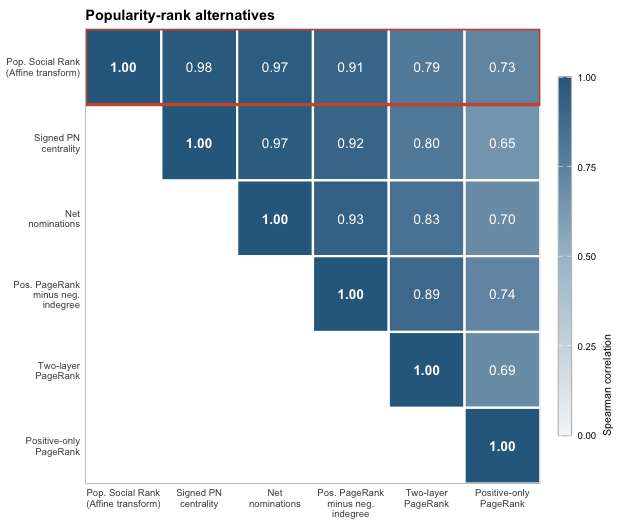

In [ ]:
# Supporting Information layout (plotting code in figures/S4_figures.R)
figure_s6 <- plot_figure_s6(alternative_ranks)
figure_s6

## Figure S7. Weight given to non-nominations

Explicit negative = 0 and explicit positive = 2 are kept; the weight of
“not named” goes from 0 to 2. The primary measure is $w = 1$.

In [ ]:
# Figure S7: keep explicit negative = 0 and explicit positive = 2, and give
# non-nominations (and offsetting pairs) a weight w from 0 to 2.
# w = 1 is the primary Social Rank.
weights_to_try <- seq(0, 2, by = 0.25)

rank_with_weight <- map_dfr(weights_to_try, function(w) {
  pagerank_by_class(case_when(nom_q4 - nom_q5 ==  1 ~ 2,
                              nom_q4 - nom_q5 == -1 ~ 0,
                              TRUE                  ~ w)) %>%
    group_by(class_id) %>%
    mutate(rank = rescale_01(value), w = w) %>%
    ungroup()
})

reference_weight_agreement <- rank_with_weight %>%
  left_join(students %>% select(student_id, social_rank), by = "student_id") %>%
  group_by(w, class_id) %>%
  summarise(spearman = cor(rank, social_rank, method = "spearman"), .groups = "drop")

reference_weight_agreement %>%
  group_by(w) %>%
  summarise(median = median(spearman), min = min(spearman))

w,median,min
0.00,0.8022608,0.3155215
0.25,0.9226087,0.5335397
0.50,0.9616036,0.5833333
0.75,0.9841897,0.8461538
1.00,1.0000000,1.0000000
1.25,0.9853190,0.9088235
1.50,0.9523810,0.8181818
1.75,0.8919028,0.7482517
2.00,0.7921739,0.5242941


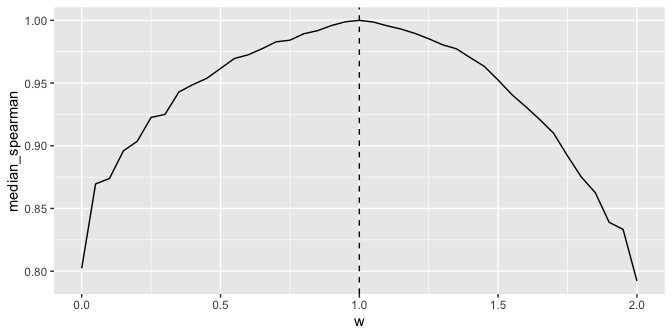

In [ ]:
# Quick look: median agreement with the primary rank across classrooms, by w
agreement_by_weight %>%
  group_by(w) %>%
  summarise(median_spearman = median(spearman)) %>%
  ggplot(aes(w, median_spearman)) +
  geom_line() +
  geom_vline(xintercept = 1, linetype = "dashed")

#### Supporting Information layout

Plotting code from `code/si/figures/S4_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S7: (A) ranks of one classroom as the weight w of non-nominations
# changes; (B) agreement with the primary order in that classroom; (C) all
# classrooms, median in orange.
plot_figure_s7 <- function(fine_ranks, agreement_by_weight, example_class) {
  primary_line <- geom_vline(xintercept = 1, linetype = "dashed", color = "grey20", linewidth = 0.4)
  w_label <- expression("Reference weight for non-nominations (" * italic(w) * ")")
  theme_s7 <- theme_si_frame(base_size = 8, l_axes = TRUE) +
    theme(plot.title = element_text(hjust = 0), plot.title.position = "panel")
  x_axis <- scale_x_continuous(limits = c(0, 2), breaks = c(0.5, 1, 1.5, 2), expand = c(0, 0))
  y_agreement <- scale_y_continuous(limits = c(0.5, 1.01), breaks = c(0.5, 0.75, 1),
                                    labels = c("0.5", "0.75", "1"), expand = c(0, 0))
  example <- fine_ranks %>% filter(class_id == example_class)
  n_example <- n_distinct(example$student_id)

  panel_a <- ggplot(example, aes(w, rank, group = student_id, color = social_rank)) +
    geom_line(linewidth = 0.6) +
    primary_line +
    annotate("text", x = 1, y = 1.04, label = "primary~(italic(w) == 1)", parse = TRUE,
             size = 2.6, color = color_text) +
    scale_color_gradient(low = "#C9D0DE", high = "#2E4A6B") +
    scale_y_continuous(breaks = c(0, 0.5, 1), labels = c("0", "0.5", "1")) +
    x_axis +
    labs(title = bquote(bold("A. One classroom: Social Rank vs.") ~ italic(w) ~ (italic(n) == .(n_example))),
         x = w_label, y = "Social Rank (normalized PageRank)") +
    theme_s7

  panel_b <- agreement_by_weight %>%
    filter(class_id == example_class) %>%
    pivot_longer(c(spearman, pairs), names_to = "measure") %>%
    mutate(measure = factor(measure, levels = c("spearman", "pairs"),
                            labels = c("Spearman rank correlation", "Pairwise orderings preserved"))) %>%
    ggplot(aes(w, value, color = measure, linetype = measure)) +
    geom_line(linewidth = 0.9) +
    primary_line +
    scale_color_manual(values = c(color_highlight, "#7A86A8"), name = NULL) +
    scale_linetype_manual(values = c("solid", "dotted"), name = NULL) +
    x_axis + y_agreement +
    labs(title = "B. One classroom: order is preserved", x = w_label,
         y = "Agreement with primary order") +
    theme_s7 +
    theme(legend.position = c(0.55, 0.12), legend.key.width = unit(0.7, "cm"),
          legend.key.height = unit(0.3, "cm"), legend.spacing.y = unit(0, "pt"),
          legend.text = element_text(size = 6.5))

  band <- agreement_by_weight %>%
    group_by(w) %>%
    summarise(median = median(spearman), low = quantile(spearman, 0.1), high = quantile(spearman, 0.9))
  legend_c <- c("Median across classrooms", "10\u201390th percentile", "Individual classrooms")

  panel_c <- ggplot() +
    geom_line(data = agreement_by_weight, aes(w, spearman, group = class_id, linetype = legend_c[3]),
              color = "#C9D0DE", linewidth = 0.25) +
    geom_ribbon(data = band, aes(w, ymin = low, ymax = high, fill = legend_c[2]), alpha = 0.25) +
    geom_line(data = band, aes(w, median, color = legend_c[1]), linewidth = 1) +
    primary_line +
    scale_color_manual(values = setNames(color_highlight, legend_c[1]), name = NULL) +
    scale_fill_manual(values = setNames(color_highlight, legend_c[2]), name = NULL) +
    scale_linetype_manual(values = setNames("solid", legend_c[3]), name = NULL) +
    x_axis + y_agreement +
    labs(title = bquote(bold("C. All classrooms") ~ (italic(k) == .(n_distinct(agreement_by_weight$class_id)))),
         x = w_label, y = "Spearman vs. primary order") +
    guides(color = guide_legend(order = 1), fill = guide_legend(order = 2),
           linetype = guide_legend(order = 3, override.aes = list(color = "#C9D0DE", linewidth = 0.5))) +
    theme_s7 +
    theme(legend.position = c(0.55, 0.14), legend.spacing.y = unit(0, "pt"),
          legend.margin = margin(0, 2, 0, 2), legend.key.height = unit(0.3, "cm"),
          legend.key.width = unit(0.7, "cm"), legend.text = element_text(size = 6.5),
          legend.background = element_rect(fill = alpha("white", 0.85), color = NA))

  figure_s7 <- (panel_a + panel_b + panel_c) +
    figure_title(paste("Reference-weight robustness of popularity-based Social Rank:",
                       "the within-class ordering is preserved"), size = 10)
  figure_s7
}

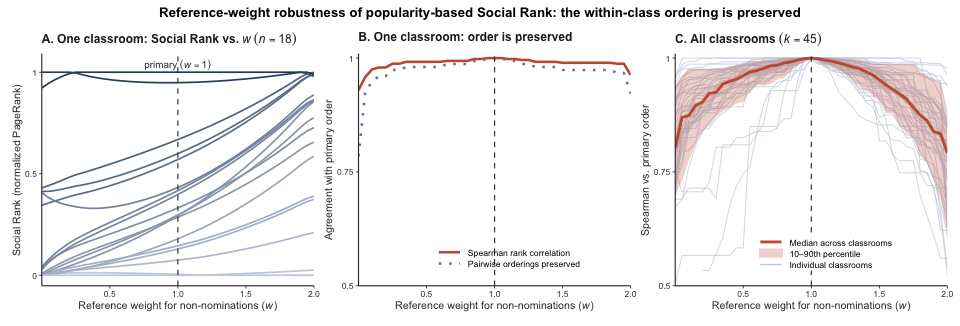

In [ ]:
# Supporting Information layout (plotting code in figures/S4_figures.R)
figure_s7 <- plot_figure_s7(fine_ranks, agreement_by_weight, example_class)
figure_s7

## Table S9. Social Rank and student characteristics

### Panel A. Correlations with Social Rank

`01_build_measures.R` standardizes nomination counts and continuous
variables within classrooms. The within-classroom correlations remove
classroom means.

In [ ]:
# Table S9, Panel A: correlations between Social Rank and other student
# characteristics. Nomination counts and continuous variables are turned into
# within-classroom z-scores. "Within-class" correlations remove the classroom
# mean of both variables first. SE = sqrt((1 - r^2) / (n - 2)).

# The within-classroom z-scores come from 01_build_measures.R (step
# "student-covariates"); here they only get the short names used below.
correlates <- students %>%
  transmute(student_id, class_id, social_rank, female, repeated_grade,
            nom_q1 = received_q1_z, nom_q2 = received_q2_z, nom_q3 = received_q3_z,
            nom_q4 = received_q4_z, nom_q5 = received_q5_z, nom_q6 = received_q6_z,
            nom_q7 = received_q7_z, nom_q8 = received_q8_z, nom_q9 = received_q9_z,
            net_popularity = net_popularity_z,
            aggression = aggression_z, prosociality = prosociality_z,
            attendance = attendance_z, gpa = gpa_z, age = age_z)

correlate_labels <- c(
  nom_q3 = "Best-friend nominations", nom_q1 = "Most-like-to-hang-out nominations",
  nom_q2 = "Least-like-to-hang-out nominations", net_popularity = "Net popularity nominations",
  nom_q4 = "Most-popular nominations (Q4)", nom_q5 = "Not-popular nominations (Q5)",
  nom_q6 = "Initiate-fights nominations (Q6)", nom_q7 = "Make-fun-of-others nominations (Q7)",
  nom_q8 = "Kind-to-others nominations (Q8)", nom_q9 = "Cooperative nominations (Q9)",
  aggression = "Aggression composite", prosociality = "Prosociality composite",
  attendance = "Attendance (within-class z)", gpa = "GPA (within-class z)",
  age = "Age (within-class z)", female = "Sex (female indicator)",
  repeated_grade = "Grade repetition (repeated indicator)"
)

correlation_row <- function(variable) {
  d <- correlates %>%
    select(class_id, social_rank, x = all_of(variable)) %>%
    filter(!is.na(x)) %>%
    group_by(class_id) %>%
    mutate(rank_within = social_rank - mean(social_rank), x_within = x - mean(x)) %>%
    ungroup()
  r <- c(pooled_pearson  = cor(d$social_rank, d$x),
         pooled_spearman = cor(d$social_rank, d$x, method = "spearman"),
         within_pearson  = cor(d$rank_within, d$x_within),
         within_spearman = cor(d$rank_within, d$x_within, method = "spearman"))
  tibble(measure = correlate_labels[[variable]], n = nrow(d),
         statistic = names(r), r = r, se = sqrt((1 - r^2) / (nrow(d) - 2)))
}

table_s9_a <- map_dfr(names(correlate_labels), correlation_row)

table_s9_a %>%
  select(measure, statistic, r) %>%
  pivot_wider(names_from = statistic, values_from = r) %>%
  mutate(across(where(is.numeric), ~ round(.x, 3)))

measure,pooled_pearson,pooled_spearman,within_pearson,within_spearman
Best-friend nominations,0.495,0.458,0.527,0.498
Most-like-to-hang-out nominations,0.523,0.494,0.556,0.534
Least-like-to-hang-out nominations,-0.177,-0.159,-0.188,-0.174
Net popularity nominations,0.924,0.928,0.983,0.990
Most-popular nominations (Q4),0.806,0.769,0.858,0.842
Not-popular nominations (Q5),-0.690,-0.694,-0.735,-0.756
Initiate-fights nominations (Q6),0.194,0.176,0.207,0.180
Make-fun-of-others nominations (Q7),0.159,0.116,0.169,0.122
Kind-to-others nominations (Q8),0.277,0.249,0.295,0.270
Cooperative nominations (Q9),0.338,0.296,0.360,0.318


### Panel B. Differences by guardian education

The public data support the guardian education comparison.

In [ ]:
# Table S9, Panel B: does Social Rank differ by guardian education (4 levels)?
# p-values from OLS and from a model with classroom FE (clustered SE), and the
# within-classroom partial R2 of the education categories.
# (Religion is also in the SI table; it is not part of the public data.)
ols_model <- lm(social_rank ~ guardian_education, data = students)
fe_model  <- felm(social_rank ~ guardian_education | class_id | 0 | class_id,
                  data = students %>% mutate(class_id = factor(class_id)))
fe_only   <- felm(social_rank ~ 1 | class_id, data = students %>% mutate(class_id = factor(class_id)))

table_s9_b <- tibble(
  characteristic = "Guardian education (4 levels)",
  ols_p          = anova(lm(social_rank ~ 1, data = students), ols_model)$`Pr(>F)`[2],
  # joint test that all education coefficients are zero (clustered)
  fe_cluster_p   = lfe::waldtest(fe_model, seq_along(coef(fe_model)))[["p.F"]],
  partial_r2     = 1 - sum(residuals(fe_model)^2) / sum(residuals(fe_only)^2),
  n              = nrow(students)
)

table_s9_b

characteristic,ols_p,fe_cluster_p,partial_r2,n
Guardian education (4 levels),0.4460258,0.1605008,0.0087315,859


## Figure S8. Social Rank and student characteristics

Panels A-O: within-classroom z-scores against Social Rank, with binned
means and a linear fit. Panels P, Q and S: Social Rank by sex, guardian
education and grade repetition. (The SI figure also shows religion,
which is not part of the public data.)

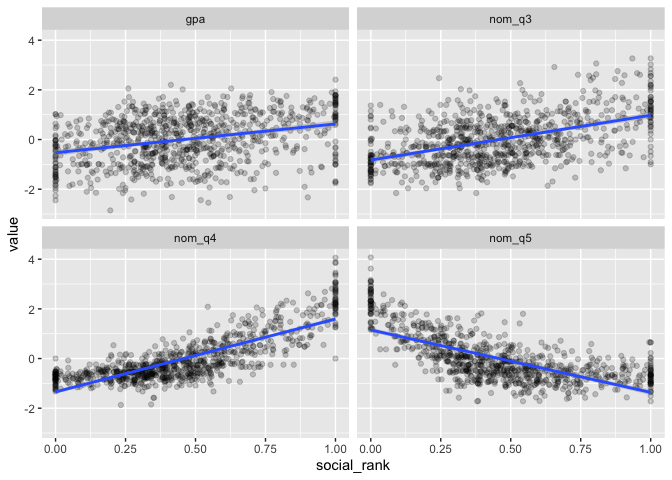

In [ ]:
# Figure S8: Social Rank against each student characteristic. Gray points are
# children; black points are binned means with 95% CI; the orange line is a
# linear fit, with the pooled Pearson correlation in the box.
# Quick look: Social Rank against a few characteristics
correlates %>%
  select(social_rank, nom_q3, nom_q4, nom_q5, gpa) %>%
  pivot_longer(-social_rank) %>%
  ggplot(aes(social_rank, value)) +
  geom_point(alpha = 0.2) +
  geom_smooth(method = "lm") +
  facet_wrap(~ name)

#### Supporting Information layout

Plotting code from `code/si/figures/S4_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S8: Social Rank against each student characteristic (gray: children;
# black: binned means with 95% CI; orange: linear fit and Pearson correlation),
# and box plots for the categorical characteristics.
plot_figure_s8 <- function(correlates, students) {
  s8_titles <- c(
    nom_q3 = "A. Best friends", nom_q1 = "B. Most like to hang out",
    nom_q2 = "C. Least like to hang out", net_popularity = "D. Net popularity",
    nom_q4 = "E. Most popular", nom_q5 = "F. Not popular",
    nom_q6 = "G. Initiate fights", nom_q7 = "H. Make fun of others",
    nom_q8 = "I. Kind to others", nom_q9 = "J. Cooperative",
    aggression = "K. Aggression (composite)", prosociality = "L. Prosociality (composite)",
    attendance = "M. Attendance previous term", gpa = "N. Overall GPA previous term",
    age = "O. Age (within-class)"
  )
  theme_s8 <- theme_si_frame(base_size = 7) +
    theme(axis.title.y = element_text(size = 6))
  x_rank <- scale_x_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2))

  # One scatter panel: children (gray), binned means with 95% CI (black),
  # linear fit and Pearson correlation (orange)
  scatter_panel <- function(variable, y_title = NULL) {
    data <- correlates %>%
      transmute(social_rank, value = .data[[variable]]) %>%
      filter(!is.na(value))
    test <- cor.test(data$social_rank, data$value)
    label <- sprintf("R = %.2f, %s", test$estimate, format_p(test$p.value))
    ggplot(data, aes(social_rank, value)) +
      geom_point(color = color_slate, alpha = 0.25, size = 0.4,
                 position = position_jitter(width = 0.005, height = 0.05, seed = 1)) +
      geom_smooth(method = "lm", formula = y ~ x, color = color_highlight, fill = color_highlight,
                  alpha = 0.2, linewidth = 0.6) +
      stat_summary_bin(fun.data = mean_cl_normal, bins = 10, size = 0.15, linewidth = 0.3) +
      annotate("label", x = 0.5, y = -2.7, label = label, color = color_highlight, size = 2.1,
               fontface = "bold", label.size = 0.3, label.padding = unit(0.12, "lines")) +
      coord_cartesian(ylim = c(-3, 3.2)) +
      scale_y_continuous(breaks = -3:3) +
      x_rank +
      labs(title = s8_titles[[variable]], x = NULL, y = y_title) +
      theme_s8
  }

  # One box-plot panel for a categorical characteristic, group labels above
  # the boxes, a classroom-clustered joint test, and partial R2.
  box_panel <- function(data, group, title, fills, y_title = NULL) {
    data <- data %>%
      filter(!is.na(.data[[group]])) %>%
      mutate(group = .data[[group]], class_id = factor(class_id))
    fit <- felm(social_rank ~ group | class_id | 0 | class_id, data = data)
    classroom_only <- felm(social_rank ~ 1 | class_id, data = data)
    group_p <- lfe::waldtest(fit, seq_along(coef(fit)), type = "cluster")[["p.F"]]
    partial_r2 <- 1 - sum(residuals(fit)^2) / sum(residuals(classroom_only)^2)
    counts <- data %>% count(group) %>%
      mutate(y = rev(seq_along(group)), label = paste0(group, " (n=", n, ")"))
    data <- data %>% left_join(counts, by = "group")
    stats <- sprintf("'group p = %.2f,  partial '*italic(R)^2*' = %.3f'", group_p, partial_r2)
    ggplot(data, aes(social_rank, y)) +
      geom_point(color = color_slate, alpha = 0.25, size = 0.4,
                 position = position_jitter(height = 0.12, seed = 1)) +
      geom_boxplot(aes(group = y, fill = group), color = "grey25", alpha = 0.75, width = 0.45,
                   outlier.shape = NA, linewidth = 0.3, coef = Inf) +
      geom_text(data = counts, aes(x = 0.5, y = y + 0.42, label = label),
                fontface = "bold", size = 2.2, color = "grey20") +
      annotate("label", x = 0.5, y = 0.35, label = stats, parse = TRUE,
               color = color_highlight, size = 2.1, fontface = "bold", label.size = 0.3) +
      scale_fill_manual(values = setNames(fills, counts$group)) +
      scale_y_continuous(limits = c(0.1, nrow(counts) + 0.6), breaks = NULL) +
      x_rank +
      labs(title = title, x = NULL, y = y_title) +
      theme_s8
  }
  blues <- function(n) colorRampPalette(c("#DCE6F0", "#4E6E8E"))(n)

  categorical <- students %>%
    mutate(sex = factor(if_else(female == 1, "Female", "Male"), levels = c("Male", "Female")),
           # the two primary categories are merged into "Primary or less", as in the SI
           guardian = str_remove(guardian_education, "^[0-9]+ "),
           guardian = if_else(str_detect(guardian, "^Primary"), "Primary or less", guardian),
           guardian = factor(guardian, levels = unique(guardian[order(guardian_education)])),
           repetition = factor(if_else(repeated_grade == 1, "Repeated", "Not repeated"),
                               levels = c("Not repeated", "Repeated")))
  n_guardian <- n_distinct(na.omit(categorical$guardian))

  y_titles <- c(nom_q3 = "Peer nominations (Z-score)", nom_q4 = "Peer nominations (Z-score)",
                nom_q8 = "Peer nominations (Z-score)", attendance = "Z-score")
  grid_panels <- map(names(s8_titles), function(v) {
    scatter_panel(v, if (v %in% names(y_titles)) y_titles[[v]] else NULL)
  })
  sex_panel <- box_panel(categorical, "sex", "P. Sex", c(color_male, color_female), "Sex")

  # Religion (Panel R in the SI) is not part of the public data
  bottom_row <- box_panel(categorical, "guardian", "Q. Guardian education", blues(n_guardian)) +
    box_panel(categorical, "repetition", "S. Grade repetition", blues(3)[2:3]) +
    plot_layout(widths = c(2.6, 1))

  figure_s8 <- (wrap_plots(c(grid_panels, list(sex_panel)), ncol = 4) / bottom_row) +
    plot_layout(heights = c(4, 1.25)) +
    plot_annotation(title = "Popularity-based Social Rank and related student characteristics",
                    caption = "Popularity-based Social Rank (normalized PageRank)",
                    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 10),
                                  plot.caption = element_text(hjust = 0.5, size = 9)))
  figure_s8
}

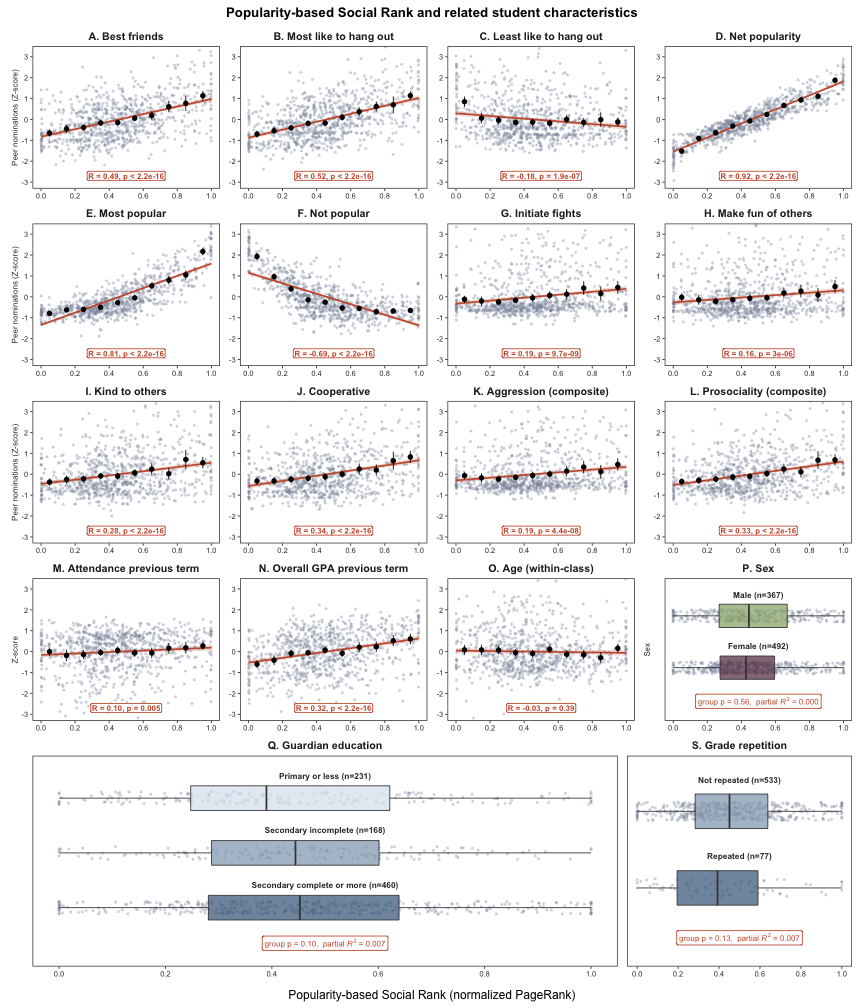

In [ ]:
# Supporting Information layout (plotting code in figures/S4_figures.R)
figure_s8 <- plot_figure_s8(correlates, students)
figure_s8

## Table S10. Distribution of the Social Rank GAP

In [ ]:
# Table S10: distribution of the Social Rank GAP
gap_distribution <- function(data, label) {
  tibble(sample = label, n = nrow(data), min = min(data$rank_gap),
         p10 = quantile(data$rank_gap, 0.10), p25 = quantile(data$rank_gap, 0.25),
         median = median(data$rank_gap), p75 = quantile(data$rank_gap, 0.75),
         p90 = quantile(data$rank_gap, 0.90), sd = sd(data$rank_gap))
}

table_s10 <- bind_rows(
  gap_distribution(dyads, "All directed interactions"),
  gap_distribution(filter(dyads, friendship == "Non-friends"), "Non-friends"),
  gap_distribution(filter(dyads, friendship %in% c("Sender declares", "Receiver declares")),
                   "Unilateral friendships"),
  gap_distribution(filter(dyads, friendship == "Mutual"), "Mutual friends")
)

table_s10 %>% mutate(across(where(is.double), ~ round(.x, 3)))

sample,n,min,p10,p25,median,p75,p90,sd
All directed interactions,17804,-1,-0.460,-0.221,0,0.221,0.460,0.354
Non-friends,13916,-1,-0.470,-0.222,0,0.222,0.470,0.361
Unilateral friendships,2600,-1,-0.450,-0.237,0,0.237,0.450,0.349
Mutual friends,1288,-1,-0.371,-0.180,0,0.180,0.371,0.295


In [ ]:
save_table(table_s7, "S4_table_s7_coding")
save_table(construction_agreement, "S4_construction_agreement")
save_table(table_s9_a, "S4_table_s9a_correlates")
save_table(table_s9_b, "S4_table_s9b_background")
save_table(table_s10, "S4_table_s10_gap_distribution")
write_csv(alternative_ranks, here("data", "generated", "alternative_ranks.csv"))

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}
save_si_figure(figure_s6, "S4_figure_s6_construction_correlations", 6.5, 5.5)
save_si_figure(figure_s7, "S4_figure_s7_reference_weight", 10, 3.4)
save_si_figure(figure_s8, "S4_figure_s8_correlates", 9, 10.5)